# Ćwiczenie 12: część 2: Radiomika — ilościowa ekstrakcja cech z obrazów medycznych

## Cel zajęć
W poprzedniej części zajęć nauczyliśmy się wyrównywać obrazy medyczne za pomocą rejestracji elastycznej (`BSplineTransform`) oraz przenosić maski segmentacyjne pomiędzy badaniami (*Mask Propagation*). Kolejnym krokiem w nowoczesnej diagnostyce wspomaganej komputerowo (**CAD / Radiomics**) jest przekształcenie wysegmentowanego obszaru zainteresowania (**ROI — *Region of Interest***) w mierzalny **wektor cech ilościowych** (*biomarkerów obrazowych*).

W tym notatniku zrealizujemy:
1. **Teorię i matematyczne podstawy cech radiomicznych** (statystyki 1. rzędu, macierze współwystępowania GLCM 2. rzędu oraz cechy morfologiczne/kształtu).
2. **Praktyczną ekstrakcję cech** na skanie tomografii komputerowej jamy brzusznej (`img-Pyelonephritis-kidney-follow-up-9070.jpeg`) z porównaniem:
   * **Prawej nerki** — objętej ostrym odmiedniczkowym zapaleniem nerek (*pyelonephritis*, widoczne niejednorodne hipodensyjne ogniska zapalne i obrzęk miąższu),
   * **Lewej nerki** — niezmienionej chorobowo (jednorodny, prawidłowo zakontrastowany miąższ nerkowy).
3. **Wizualizację i interpretację kliniczną** histogramów jasności, macierzy GLCM oraz tabeli porównawczej cech.

---
## 1. Podstawy teoretyczne: 

Zgodnie ze standardem **IBSI (*Image Biomarker Standardisation Initiative*)**, klasyczne cechy radiomiczne dzielimy na trzy główne rodziny:

### A. Cechy statystyczne pierwszego rzędu (*First-Order Statistics*)
Opisują **rozkład wartości intensywności (jasności)** pikseli lub wokseli $X = \{x_1, x_2, \dots, x_N\}$ wewnątrz maski ROI, **ignorując ich wzajemne położenie przestrzenne** (opierają się wyłącznie na histogramie obrazu).

Niech $N$ oznacza liczbę pikseli wewnątrz maski ROI, a $p(i)$ znormalizowane prawdopodobieństwo wystąpienia poziomu jasności z przedziału $i \in \{1, \dots, N_g\}$ (gdzie $\sum_{i=1}^{N_g} p(i) = 1$):

1. **Średnia (*Mean*):**
   $$\mu = \frac{1}{N} \sum_{k=1}^{N} x_k$$
   *Znaczenie kliniczne:* Określa średnie pochłanianie promieniowania (w TK wyrażone w jednostkach Hounsfielda HU lub znormalizowanej jasności). Naciek zapalny lub martwica obniżają średnią gęstość tkanki.

2. **Wariancja (*Variance*) i Odchylenie standardowe (*Standard Deviation*):**
   $$\sigma^2 = \frac{1}{N} \sum_{k=1}^{N} (x_k - \mu)^2, \qquad \sigma = \sqrt{\sigma^2}$$
   *Znaczenie kliniczne:* Mierzy rozrzut jasności wokół średniej. Wysoka wartość $\sigma$ wskazuje na współistnienie obszarów o różnej gęstości (np. obrzęk + prawidłowy miąższ).

3. **Skośność (*Skewness*):**
   $$\gamma_1 = \frac{\frac{1}{N} \sum_{k=1}^{N} (x_k - \mu)^3}{\sigma^3}$$
   *Znaczenie kliniczne:* Mierzy **asymetrię** histogramu względem wartości średniej:
   * $\gamma_1 = 0$: rozkład symetryczny,
   * $\gamma_1 < 0$ (skośność lewostronna): długi lewy ogon histogramu — obecność ciemniejszych (hipodensyjnych) ognisk wewnątrz jasnego miąższu,
   * $\gamma_1 > 0$ (skośność prawostronna): długi prawy ogon — obecność jasnych zwapnień lub ognisk silnego wzmocnienia kontrastowego.

4. **Kurtoza nadwyżkowa (*Excess Kurtosis*):**
   $$\gamma_2 = \frac{\frac{1}{N} \sum_{k=1}^{N} (x_k - \mu)^4}{\sigma^4} - 3$$
   *Znaczenie kliniczne:* Określa **smukłość (koncentrację) rozkładu** w porównaniu z rozkładem normalnym Gaussa (dla którego $\gamma_2 = 0$):
   * $\gamma_2 > 0$ (rozkład leptokurtyczny): wąski, ostry pik — zdecydowana większość pikseli ma niemal identyczną jasność (tkanka jednorodna),
   * $\gamma_2 < 0$ (rozkład platykurtyczny): rozkład spłaszczony lub wielomodalny — silna heterogeniczność tkanki.

5. **Entropia Shannona (*Entropy*):**
   $$H = -\sum_{i=1}^{N_g} p(i) \log_2\big(p(i) + \epsilon\big)$$
   *Znaczenie kliniczne:* Mierzy **nieuporządkowanie (losowość) rozkładu intensywności** w bitach. Im bardziej zróżnicowane poziomy szarości wewnątrz narządu, tym wyższa entropia.

6. **Jednolitość / Energia 1. rzędu (*Uniformity*):**
   $$U = \sum_{i=1}^{N_g} p(i)^2$$
   *Znaczenie kliniczne:* Odwrotność entropii — osiąga maksimum ($U = 1$), gdy wszystkie piksele w ROI należą do jednego przedziału jasności.

7. **Rozstęp ćwiartkowy (*IQR — Interquartile Range*):**
   $$\text{IQR} = P_{75} - P_{25}$$
   *Znaczenie kliniczne:* Odporna na wartości odstające miara rozrzutu środkowych 50% pikseli narządu.

### B. Cechy tekstury drugiego rzędu — Macierz GLCM (*Gray-Level Co-occurrence Matrix*)

Statystyki 1. rzędu nie rozróżniają sytuacji, w której ciemne piksele są skupione w jednym dużym ognisku martwiczym, od sytuacji, w której tworzą drobną „szachownicę” w całym narządzie. Do oceny **relacji przestrzennych** między sąsiadującymi pikselami służy **macierz współwystępowania poziomów szarości GLCM** (Haralick, 1973).

**Konstrukcja macierzy $P(i, j \mid d, \theta)$:**
1. Najpierw ciągłe intensywności w ROI dyskretyzujemy do $N_g$ poziomów szarości (np. $N_g = 32$ lub $64$).
2. Element macierzy $P(i, j \mid d, \theta)$ określa znormalizowane prawdopodobieństwo, że piksel o poziomie szarości $i$ sąsiaduje w odległości $d$ (np. $d = 1, 2$ px) i kierunku $\theta \in \{0^\circ, 45^\circ, 90^\circ, 135^\circ\}$ z pikselem o poziomie $j$.
3. Aby uzyskać **niezmienniczość względem obrotu** (*rotation invariance*), cechy uśredniamy po wszystkich 4 kierunkach $\theta$.

**Najważniejsze deskryptory Haralicka z macierzy GLCM:**

* **Kontrast (*Contrast*):**
  $$\text{Contrast} = \sum_{i=0}^{N_g-1} \sum_{j=0}^{N_g-1} (i - j)^2 P(i, j)$$
  Mierzy lokalne skoki jasności między sąsiednimi pikselami. Wagi $(i - j)^2$ rosną kwadratowo wraz z różnicą jasności — wysoki kontrast świadczy o obecności ostrych granic wewnątrz tkanki (np. ognisk zapalnych, torbieli, martwicy).

* **Niepodobieństwo (*Dissimilarity*):**
  $$\text{Dissimilarity} = \sum_{i=0}^{N_g-1} \sum_{j=0}^{N_g-1} |i - j| P(i, j)$$
  Podobne do kontrastu, lecz z wagą liniową $|i - j|$ (mniej wrażliwe na pojedyncze skrajne artefakty).

* **Homogeniczność (*Homogeneity / Inverse Difference Moment — IDM*):**
  $$\text{Homogeneity} = \sum_{i=0}^{N_g-1} \sum_{j=0}^{N_g-1} \frac{P(i, j)}{1 + (i - j)^2}$$
  Mierzy bliskość rozkładu elementów macierzy GLCM względem głównej przekątnej ($i = j$). Przyjmuje wartości z zakresu $[0, 1]$ — jest wysoka dla jednorodnej, zdrowej tkanki.

* **Energia GLCM (*Energy / Angular Second Moment — ASM*):**
  $$\text{ASM} = \sum_{i=0}^{N_g-1} \sum_{j=0}^{N_g-1} P(i, j)^2, \qquad \text{Energy} = \sqrt{\text{ASM}}$$
  Mierzy regularność i powtarzalność wzorca tekstury.

* **Korelacja (*Correlation*):**
  $$\text{Correlation} = \sum_{i=0}^{N_g-1} \sum_{j=0}^{N_g-1} \frac{(i - \mu_x)(j - \mu_y)}{\sigma_x \sigma_y} P(i, j)$$
  Mierzy liniową zależność poziomów szarości sąsiadujących pikseli (od $-1$ do $+1$).

### C. Cechy morfologiczne / kształtu (*Shape Features*)

Obliczane są wyłącznie na podstawie **binarnej maski segmentacyjnej ROI** (niezależnie od jasności pikseli), z obowiązkowym uwzględnieniem fizycznego rozmiaru piksela/woksela (`Spacing` z nagłówka DICOM/SimpleITK):

* **Pole powierzchni ($A$):** $A = N_{\text{ROI}} \cdot \Delta x \cdot \Delta y \;[\text{mm}^2]$ — bezpośredni wskaźnik obrzęku narządu lub wzrostu guza.
* **Obwód ($P$):** długość konturu maski w $[\text{mm}]$.
* **Cyrkularność / Zwięzłość (*Circularity*):**
  $$C = \frac{4\pi A}{P^2} \in (0, 1]$$
  Dla idealnego koła $C = 1.0$. Nieregularne, postrzępione nacieki lub ubytki w masce zwiększają obwód $P$ względem pola $A$, powodując gwałtowny spadek cyrkularności.
* **Ekscentryczność (*Eccentricity*):** $e = \sqrt{1 - (b/a)^2} \in [0, 1)$, opisuje wydłużenie elipsy dopasowanej do narządu ($a, b$ — półosie elipsy).

In [6]:
# Instalacja i import niezbędnych bibliotek
#!pip install -q SimpleITK scikit-image pandas

import SimpleITK as sitk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.ndimage import binary_erosion
from skimage.feature import graycomatrix, graycoprops
from skimage.measure import regionprops

print(f"Środowisko radiomiczne gotowe (SimpleITK {sitk.__version__})")

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


Środowisko radiomiczne gotowe (SimpleITK 2.5.7)


---
## 2. Przygotowanie obrazu TK oraz segmentacja obu nerek

Wczytujemy skan tomografii komputerowej jamy brzusznej (`img-Pyelonephritis-kidney-follow-up-9070.jpeg`) i definiujemy dwie maski binarne:
* **`mask_right` (Prawa nerka, widoczna po lewej stronie obrazu):** objęta ostrym odmiedniczkowym zapaleniem nerek (*pyelonephritis*) — powiększona obrzękowo, z licznymi ciemniejszymi (hipodensyjnymi) ogniskami zapalnymi.
* **`mask_left` (Lewa nerka, widoczna po prawej stronie obrazu):** nerka kontrolna o prawidłowej wielkości i jednorodnym zakontrastowaniu kory oraz rdzenia.

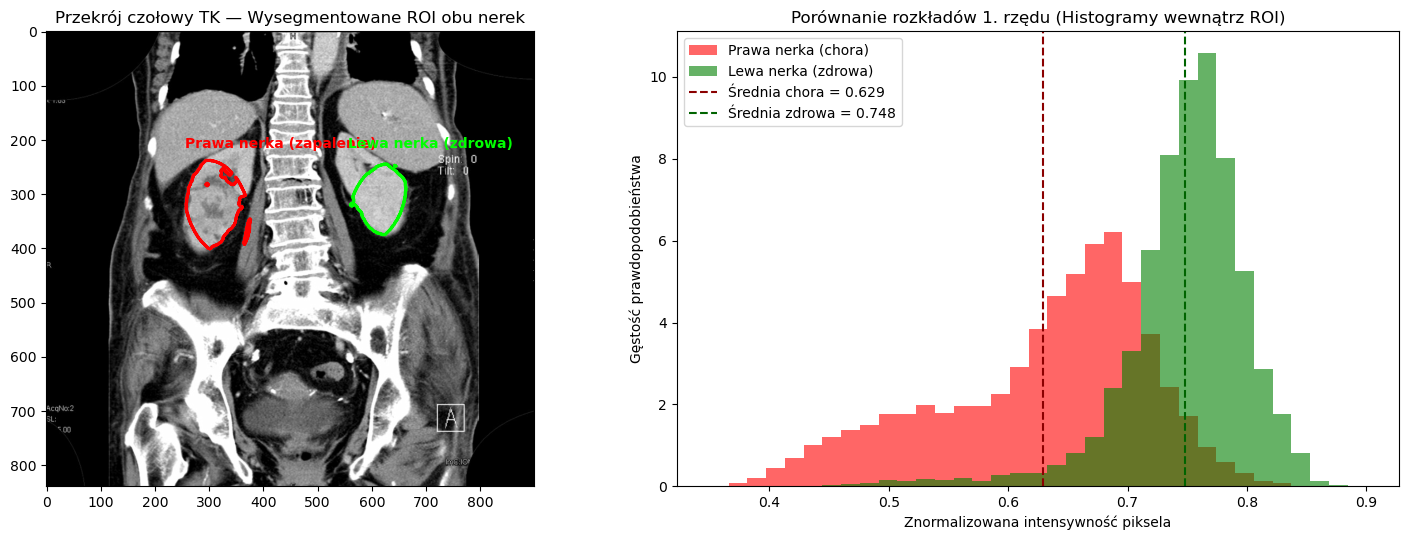

In [11]:
# 1. Wczytanie obrazu TK za pomocą SimpleITK
ct_raw = sitk.ReadImage("sample photos/jpeg/img-Pyelonephritis-kidney-follow-up-9070.jpeg", sitk.sitkFloat32)
ct_img = sitk.Cast(ct_raw / 255.0, sitk.sitkFloat32)
ct_img.SetSpacing((1.0, 1.0))  # przyjmujemy 1.0 mm x 1.0 mm
ct_img.SetOrigin((0.0, 0.0))

ct_np = sitk.GetArrayFromImage(ct_img)
H, W = ct_np.shape
y, x = np.mgrid[0:H, 0:W].astype(np.float32)

# 2. Segmentacja PRAWEJ nerki (chora - po lewej stronie przekroju TK)
theta_r = np.radians(-18.0)
xr = (x - 315.0) * np.cos(theta_r) + (y - 325.0) * np.sin(theta_r)
yr = -(x - 315.0) * np.sin(theta_r) + (y - 325.0) * np.cos(theta_r)
roi_right = ((xr / 58.0)**2 + (yr / 92.0)**2) <= 1.0
mask_right_np = binary_erosion(roi_right & (ct_np > 0.35), iterations=2).astype(np.uint8)

# 3. Segmentacja LEWEJ nerki (zdrowa - po prawej stronie przekroju TK)
theta_l = np.radians(24.0)
xl = (x - 610.0) * np.cos(theta_l) + (y - 316.0) * np.sin(theta_l)
yl = -(x - 610.0) * np.sin(theta_l) + (y - 316.0) * np.cos(theta_l)
roi_left = ((xl / 48.0)**2 + (yl / 78.0)**2) <= 1.0
mask_left_np = binary_erosion(roi_left & (ct_np > 0.35), iterations=2).astype(np.uint8)

# Konwersja masek do obiektów SimpleITK (z zachowaniem metadanych Spacing/Origin)
mask_right_sitk = sitk.GetImageFromArray(mask_right_np)
mask_right_sitk.CopyInformation(ct_img)

mask_left_sitk = sitk.GetImageFromArray(mask_left_np)
mask_left_sitk.CopyInformation(ct_img)

# Wizualizacja obu obszarów ROI oraz porównanie histogramów intensywności
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

ax[0].imshow(ct_np, cmap='gray', vmin=0, vmax=1)
ax[0].contour(mask_right_np, colors='red', linewidths=1.8)
ax[0].contour(mask_left_np, colors='lime', linewidths=1.8)
ax[0].text(255, 215, "Prawa nerka (zapalenie)", color='red', fontweight='bold', fontsize=10)
ax[0].text(555, 215, "Lewa nerka (zdrowa)", color='lime', fontweight='bold', fontsize=10)
ax[0].set_title("Przekrój czołowy TK — Wysegmentowane ROI obu nerek")

vals_r = ct_np[mask_right_np > 0]
vals_l = ct_np[mask_left_np > 0]
ax[1].hist(vals_r, bins=35, range=(0.35, 0.90), density=True, alpha=0.6, color='red', label='Prawa nerka (chora)')
ax[1].hist(vals_l, bins=35, range=(0.35, 0.90), density=True, alpha=0.6, color='green', label='Lewa nerka (zdrowa)')
ax[1].axvline(np.mean(vals_r), color='darkred', linestyle='--', linewidth=1.5, label=f'Średnia chora = {np.mean(vals_r):.3f}')
ax[1].axvline(np.mean(vals_l), color='darkgreen', linestyle='--', linewidth=1.5, label=f'Średnia zdrowa = {np.mean(vals_l):.3f}')
ax[1].set_xlabel("Znormalizowana intensywność piksela")
ax[1].set_ylabel("Gęstość prawdopodobieństwa")
ax[1].set_title("Porównanie rozkładów 1. rzędu (Histogramy wewnątrz ROI)")
ax[1].legend()

plt.tight_layout()
plt.show()

---
## 3. Implementacja ekstraktora cech radiomicznych (1. rząd + GLCM + Kształt)

**Ważny szczegół techniczny przy obliczaniu macierzy GLCM wewnątrz nieregularnego ROI:**
funkcja `skimage.feature.graycomatrix()` przyjmuje prostokątny wycinek obrazu (*bounding box*). Aby piksele tła leżące poza maską nerki nie zafałszowały statystyk tekstury:
1. Intensywności pikseli wewnątrz maski kwantujemy na $N_g = 32$ przedziałów ($0, 1, \dots, 31$) w stałym zakresie $[0.35, 0.90]$ (dzięki stałemu zakresowi kwantyzacji cechy obu nerek są w pełni porównywalne!).
2. Pikselom spoza maski przypisujemy dodatkowy indeks tła `levels = 32`.
3. Po obliczeniu macierzy o wymiarach $33 \times 33$ odcinamy ostatni wiersz i ostatnią kolumnę (`glcm[:32, :32]`), zachowując wyłącznie pary pikseli należące w całości do miąższu nerki, a następnie normalizujemy macierz tak, aby jej suma wynosiła $1$.

In [14]:
def extract_radiomic_features(image_sitk, mask_sitk, levels=32, intensity_range=(0.35, 0.90)):
    """
    Ekstrahuje 16 cech radiomicznych z obrazu SimpleITK wewnątrz binarnej maski ROI:
    - 7 cech statystycznych 1. rzędu (histogram),
    - 5 cech tekstury 2. rzędu (macierz GLCM uśredniona po 4 kierunkach i 2 odległościach),
    - 4 cechy geometryczne / kształtu (z uwzględnieniem fizycznego Spacing).
    """
    img_np = sitk.GetArrayFromImage(image_sitk)
    mask_np = sitk.GetArrayFromImage(mask_sitk) > 0
    spacing = image_sitk.GetSpacing()  # (dx, dy) w mm

    vals = img_np[mask_np]
    v_min, v_max = intensity_range

    # ---------------------------------------------------------
    # 1. CECHY STATYSTYCZNE PIERWSZEGO RZĘDU (First-Order)
    # ---------------------------------------------------------
    mean_val = float(np.mean(vals))
    std_val = float(np.std(vals))
    skew_val = float(stats.skew(vals))
    kurt_val = float(stats.kurtosis(vals))  # kurtoza nadwyżkowa (Fisher)
    iqr_val = float(np.percentile(vals, 75) - np.percentile(vals, 25))

    # Histogram znormalizowany do rozkładu prawdopodobieństwa p(i)
    hist, _ = np.histogram(vals, bins=levels, range=(v_min, v_max), density=False)
    p = hist / (np.sum(hist) + 1e-12)
    p_nonzero = p[p > 0]
    entropy_val = float(-np.sum(p_nonzero * np.log2(p_nonzero)))
    uniformity_val = float(np.sum(p ** 2))

    # ---------------------------------------------------------
    # 2. CECHY TEKSTURY DRUGIEGO RZĘDU (GLCM)
    # ---------------------------------------------------------
    ys, xs = np.where(mask_np)
    y0, y1 = ys.min(), ys.max() + 1
    x0, x1 = xs.min(), xs.max() + 1

    patch = img_np[y0:y1, x0:x1]
    patch_mask = mask_np[y0:y1, x0:x1]

    # Kwantyzacja poziomów szarości do [0 .. levels-1]; tło otrzymuje kod `levels`
    quant = np.clip(np.floor((patch - v_min) / (v_max - v_min) * (levels - 1)), 0, levels - 1).astype(np.uint8)
    quant[~patch_mask] = levels

    glcm_raw = graycomatrix(
        quant,
        distances=[1, 2],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=levels + 1,
        symmetric=True,
        normed=False
    )

    # Odcięcie tła i normalizacja macierzy GLCM wyłącznie dla pikseli wewnątrz ROI
    glcm = glcm_raw[:levels, :levels, :, :].astype(np.float64)
    sums = glcm.sum(axis=(0, 1), keepdims=True)
    glcm = np.divide(glcm, sums, out=np.zeros_like(glcm), where=sums > 0)

    contrast = float(np.mean(graycoprops(glcm, 'contrast')))
    dissimilarity = float(np.mean(graycoprops(glcm, 'dissimilarity')))
    homogeneity = float(np.mean(graycoprops(glcm, 'homogeneity')))
    energy_glcm = float(np.mean(graycoprops(glcm, 'energy')))
    correlation = float(np.mean(graycoprops(glcm, 'correlation')))

    # ---------------------------------------------------------
    # 3. CECHY MORFOLOGICZNE / KSZTAŁTU (Shape)
    # ---------------------------------------------------------
    props = regionprops(mask_np.astype(np.uint8))[0]
    px_area = spacing[0] * spacing[1]
    area_mm2 = float(props.area * px_area)
    perim_mm = float(props.perimeter * np.sqrt(px_area))
    circularity = float(4.0 * np.pi * area_mm2 / (perim_mm ** 2 + 1e-8))
    eccentricity = float(props.eccentricity)

    features = {
        "1st_Mean (Średnia)": mean_val,
        "1st_Std (Odch. standardowe)": std_val,
        "1st_Skewness (Skośność)": skew_val,
        "1st_Kurtosis (Kurtoza)": kurt_val,
        "1st_Entropy (Entropia [bit])": entropy_val,
        "1st_Uniformity (Jednolitość)": uniformity_val,
        "1st_IQR (Rozstęp ćwiartkowy)": iqr_val,
        "GLCM_Contrast (Kontrast)": contrast,
        "GLCM_Dissimilarity (Niepodobieństwo)": dissimilarity,
        "GLCM_Homogeneity (Homogeniczność)": homogeneity,
        "GLCM_Energy (Energia ASM)": energy_glcm,
        "GLCM_Correlation (Korelacja)": correlation,
        "Shape_Area [mm^2]": area_mm2,
        "Shape_Perimeter [mm]": perim_mm,
        "Shape_Circularity (Cyrkularność)": circularity,
        "Shape_Eccentricity (Ekscentryczność)": eccentricity
    }

    # Zwracamy również uśrednioną macierz GLCM (d=1) do wizualizacji
    glcm_mean_d1 = np.mean(glcm[:, :, 0, :], axis=2)
    return features, glcm_mean_d1

# Ekstrakcja cech dla obu nerek
feat_right, glcm_right = extract_radiomic_features(ct_img, mask_right_sitk)
feat_left, glcm_left = extract_radiomic_features(ct_img, mask_left_sitk)

# Zestawienie w tabeli Pandas z obliczeniem różnicy procentowej
df_radiomics = pd.DataFrame({
    "Prawa nerka (Zapalenie)": feat_right,
    "Lewa nerka (Zdrowa)": feat_left
})
df_radiomics["Różnica (Chora vs Zdrowa) [%]"] = (
    (df_radiomics["Prawa nerka (Zapalenie)"] - df_radiomics["Lewa nerka (Zdrowa)"])
    / (df_radiomics["Lewa nerka (Zdrowa)"].abs() + 1e-8) * 100.0
)

display(df_radiomics.round(4))

,Prawa nerka (Zapalenie),Lewa nerka (Zdrowa),Różnica (Chora vs Zdrowa) [%]
1st_Mean (Średnia),0.6294,0.7484,-15.8978
1st_Std (Odch. standardowe),0.0892,0.0527,69.3991
1st_Skewness (Skośność),-0.6529,-1.6713,60.9334
1st_Kurtosis (Kurtoza),-0.2784,5.6814,-104.9009
1st_Entropy (Entropia [bit]),4.2708,3.4576,23.5195
1st_Uniformity (Jednolitość),0.0624,0.1170,-46.6685
1st_IQR (Rozstęp ćwiartkowy),0.1216,0.0549,121.4285
GLCM_Contrast (Kontrast),4.6261,3.5623,29.8628
GLCM_Dissimilarity (Niepodobieństwo),1.6036,1.4107,13.6736
GLCM_Homogeneity (Homogeniczność),0.4506,0.4835,-6.8045


---
## 4. Wizualizacja macierzy GLCM oraz interpretacja kliniczna wyników

Poniższa wizualizacja pokazuje, jak zmiana patologiczna odbija się w strukturze macierzy współwystępowania GLCM:
* W **zdrowej lewej nerce** prawdopodobieństwo koncentruje się w wąskim, zwartym skupisku na głównej przekątnej w obszarze wysokich jasności (poziomy $22\text{–}28$).
* W **chorej prawej nerce** macierz ulega **rozmyciu wzdłuż przekątnej** (w kierunku niższych poziomów szarości odpowiada to hipodensyjnym ogniskom zapalnym) oraz **poszerzeniu prostopadle do przekątnej** (co bezpośrednio podnosi wartość **Kontrastu** i obniża **Homogeniczność** oraz **Energię GLCM**).

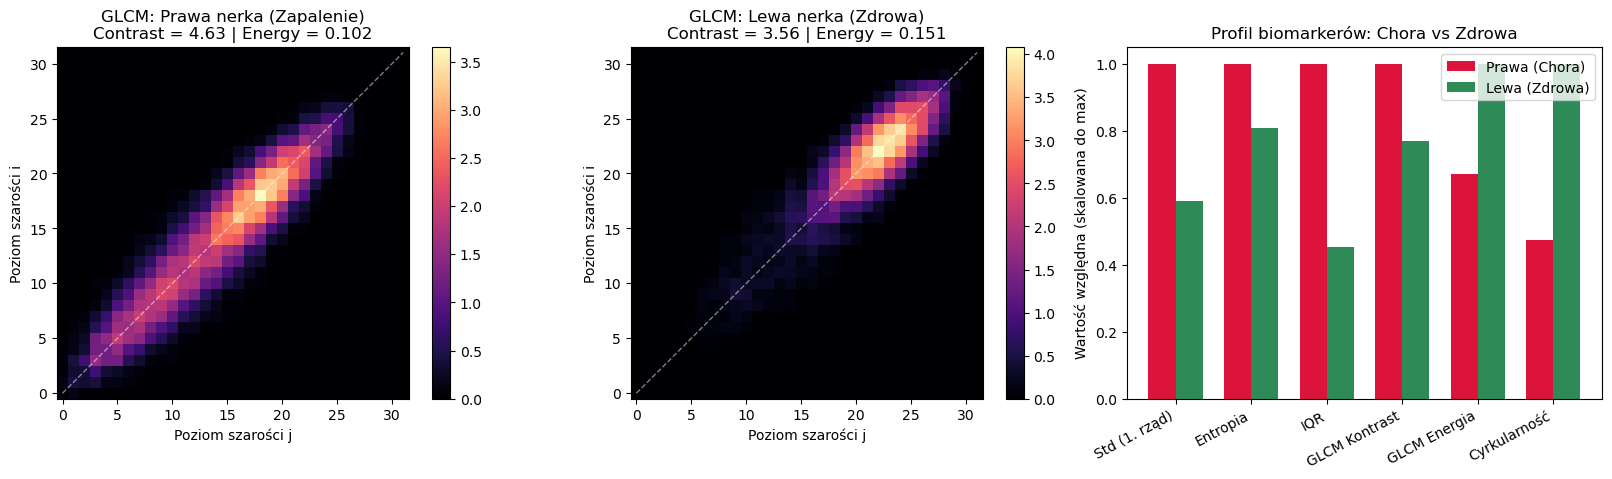

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# Panel 1: GLCM chorej nerki
im0 = ax[0].imshow(np.log1p(glcm_right * 1000), cmap='magma', origin='lower')
ax[0].plot([0, 31], [0, 31], 'w--', alpha=0.5, linewidth=1)
ax[0].set_title(f"GLCM: Prawa nerka (Zapalenie)\nContrast = {feat_right['GLCM_Contrast (Kontrast)']:.2f} | Energy = {feat_right['GLCM_Energy (Energia ASM)']:.3f}")
ax[0].set_xlabel("Poziom szarości j")
ax[0].set_ylabel("Poziom szarości i")
plt.colorbar(im0, ax=ax[0], fraction=0.046)

# Panel 2: GLCM zdrowej nerki
im1 = ax[1].imshow(np.log1p(glcm_left * 1000), cmap='magma', origin='lower')
ax[1].plot([0, 31], [0, 31], 'w--', alpha=0.5, linewidth=1)
ax[1].set_title(f"GLCM: Lewa nerka (Zdrowa)\nContrast = {feat_left['GLCM_Contrast (Kontrast)']:.2f} | Energy = {feat_left['GLCM_Energy (Energia ASM)']:.3f}")
ax[1].set_xlabel("Poziom szarości j")
ax[1].set_ylabel("Poziom szarości i")
plt.colorbar(im1, ax=ax[1], fraction=0.046)

# Panel 3: Porównanie kluczowych biomarkerów radiomicznych (znormalizowanych)
selected_keys = [
    "1st_Std (Odch. standardowe)",
    "1st_Entropy (Entropia [bit])",
    "1st_IQR (Rozstęp ćwiartkowy)",
    "GLCM_Contrast (Kontrast)",
    "GLCM_Energy (Energia ASM)",
    "Shape_Circularity (Cyrkularność)"
]
short_labels = ["Std (1. rząd)", "Entropia", "IQR", "GLCM Kontrast", "GLCM Energia", "Cyrkularność"]

vals_r_sel = np.array([feat_right[k] for k in selected_keys])
vals_l_sel = np.array([feat_left[k] for k in selected_keys])
max_v = np.maximum(vals_r_sel, vals_l_sel)

x_idx = np.arange(len(short_labels))
width = 0.36
ax[2].bar(x_idx - width / 2, vals_r_sel / max_v, width, color='crimson', label='Prawa (Chora)')
ax[2].bar(x_idx + width / 2, vals_l_sel / max_v, width, color='seagreen', label='Lewa (Zdrowa)')
ax[2].set_xticks(x_idx)
ax[2].set_xticklabels(short_labels, rotation=28, ha='right')
ax[2].set_ylabel("Wartość względna (skalowana do max)")
ax[2].set_title("Profil biomarkerów: Chora vs Zdrowa")
ax[2].legend()

plt.tight_layout()
plt.show()

---
### Podsumowanie obserwacji radiomicznych

| Grupa cech | Obserwowana zmiana (Prawa chora vs. Lewa zdrowa) | Interpretacja fizyczna i kliniczna |
| :--- | :--- | :--- |
| **Statystyki 1. rzędu** | Niższa **Średnia** ($0.629$ vs $0.748$), wyraźnie wyższe **Odch. std.** ($+69\%$), **IQR** ($+121\%$) i **Entropia** ($4.27$ vs $3.46$ bit), spadek **Kurtozy** ($-0.28$ vs $+5.68$) | Zdrowy miąższ daje ostry, wąski pik jasności (wysoka kurtoza, niska entropia). Naciek zapalny rozmywa histogram w lewo i spłaszcza rozkład. |
| **Tekstura GLCM (2. rząd)** | Wyższy **Kontrast** ($4.63$ vs $3.56$, $+30\%$) oraz spadek **Energii ASM** ($0.102$ vs $0.151$, $-33\%$) i **Homogeniczności** | Ogniska zapalne tworzą liczne lokalne przejścia między jasnym miąższem a ciemniejszymi obszarami niedokrwienia/obrzęku. |
| **Kształt (Shape)** | Większe **Pole powierzchni** ($+34\%$) i niższa **Cyrkularność** ($0.36$ vs $0.77$) | Obrzęk powiększa przekrój nerki, a hipodensyjne ubytki zaburzają gładki obrys maski. |